# Online Retail — Basic Stats & Data Quality

This notebook inspects the **Online Retail** transaction dataset: shape, types, key distributions, and immediate data-quality issues.

In [2]:

from pathlib import Path
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

possible_paths = [
    Path("data/raw/Online Retail.xlsx"),
    Path("../data/raw/Online Retail.xlsx")
]

xlsx_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if xlsx_path is None:
    raise FileNotFoundError("Online Retail.xlsx not found.")

df = pd.read_excel(
    xlsx_path,
    usecols=[
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
)

df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


## Basic stats

In [43]:
print("Shape (rows, columns):", df.shape)
print("\nColumn dtypes:")
print(df.dtypes)
print("\nMemory usage:")
print(df.memory_usage(deep=True).to_frame("bytes"))

Shape (rows, columns): (541909, 8)

Column dtypes:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

Memory usage:
                bytes
Index             132
InvoiceNo    19694544
StockCode    20543500
Description  40929081
Quantity      4335272
InvoiceDate   4335272
UnitPrice     4335272
CustomerID    4335272
Country      33802226


In [44]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,"541,909.00","25,900.00","573,585.00","1,114.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.00",NaN,NaN,NaN,9.55,"-80,995.00",1.00,3.00,10.00,"80,995.00",218.08
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,"541,909.00",NaN,NaN,NaN,4.61,"-11,062.06",1.25,2.08,4.13,"38,970.00",96.76
CustomerID,"406,829.00",NaN,NaN,NaN,"15,287.69","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00","1,713.60"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [45]:
print("Date range:", df["InvoiceDate"].min(), "→", df["InvoiceDate"].max())
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Unique stock codes:", df["StockCode"].nunique())
print("Unique descriptions:", df["Description"].nunique())
print("Unique customers (non-null):", df["CustomerID"].nunique())
print("Countries:", df["Country"].nunique())
print("\nTop 10 countries by line items:")
print(df["Country"].value_counts().head(10))

df["Revenue"] = df["Quantity"] * df["UnitPrice"]
print("\nGross revenue (including negatives/cancellations):", f"{df['Revenue'].sum():,.2f}")

Date range: 2010-12-01 08:26:00 → 2011-12-09 12:50:00
Unique invoices: 25900
Unique stock codes: 4070
Unique descriptions: 4223
Unique customers (non-null): 4372
Countries: 38

Top 10 countries by line items:
Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

Gross revenue (including negatives/cancellations): 9,747,747.93


## Data quality observations

In [46]:
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
missing

,missing_count,missing_pct
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00
Revenue,0,0.00


In [47]:
n_dupes = df.duplicated().sum()
print("Exact duplicate rows:", n_dupes, f"({n_dupes / len(df) * 100:.2f}%)")

qty_neg = (df["Quantity"] < 0).sum()
qty_zero = (df["Quantity"] == 0).sum()
price_neg = (df["UnitPrice"] < 0).sum()
price_zero = (df["UnitPrice"] == 0).sum()

invoice_as_str = df["InvoiceNo"].astype(str)
cancelled = invoice_as_str.str.startswith("C")
print("Cancelled invoices (InvoiceNo starts with C):", cancelled.sum())
print("Negative Quantity:", qty_neg, f"({qty_neg / len(df) * 100:.2f}%)")
print("Zero Quantity:", qty_zero)
print("Negative UnitPrice:", price_neg)
print("Zero UnitPrice:", price_zero)
print("Negative qty but InvoiceNo does NOT start with C:", ((df["Quantity"] < 0) & ~cancelled).sum())
print("InvoiceNo starts with C but Quantity is not negative:", (cancelled & (df["Quantity"] >= 0)).sum())

print("\nMissing CustomerID rate:", f"{df['CustomerID'].isna().mean() * 100:.2f}%")
print("Missing Description rate:", f"{df['Description'].isna().mean() * 100:.2f}%")
print("Rows missing Description AND CustomerID:", df[df["Description"].isna() & df["CustomerID"].isna()].shape[0])

Exact duplicate rows: 5268 (0.97%)
Cancelled invoices (InvoiceNo starts with C): 9288
Negative Quantity: 10624 (1.96%)
Zero Quantity: 0
Negative UnitPrice: 2
Zero UnitPrice: 2515
Negative qty but InvoiceNo does NOT start with C: 1336
InvoiceNo starts with C but Quantity is not negative: 0

Missing CustomerID rate: 24.93%
Missing Description rate: 0.27%
Rows missing Description AND CustomerID: 1454


In [48]:
# Non-product / administrative stock codes often seen in this dataset
stock = df["StockCode"].astype(str).str.strip().str.upper()
special_mask = stock.str.fullmatch(r"[A-Z]+\d*") | stock.isin(
    ["POST", "DOT", "M", "D", "S", "AMAZONFEE", "BANK CHARGES", "CRUK", "PADS", "B", "C2"]
)
print("Likely non-product stock codes (sample counts):")
print(df.loc[special_mask, "StockCode"].astype(str).str.upper().value_counts().head(20))

print("\nNegative UnitPrice rows:")
display(df[df["UnitPrice"] < 0][["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "Country"]])

print("Missing Description sample:")
display(df[df["Description"].isna()].head(8))

Likely non-product stock codes (sample counts):
StockCode
POST            1256
DOT              710
M                572
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
DCGSSBOY          11
DCGS0003           5
PADS               4
B                  3
DCGS0076           2
DCGS0070           2
DCGS0069           2
DCGS0055           1
DCGS0072           1
DCGS0074           1
Name: count, dtype: int64

Negative UnitPrice rows:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,"-11,062.06",NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,"-11,062.06",NaN,United Kingdom


Missing Description sample:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom,0.00
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.00,NaN,United Kingdom,0.00
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.00,NaN,United Kingdom,0.00
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.00,NaN,United Kingdom,0.00
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom,0.00
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom,0.00
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom,0.00
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.00,NaN,United Kingdom,0.00


### Immediate observations

- **CustomerID is missing on 135,080 rows (24.93%)**. Those lines cannot be used for customer-level work (RFM, cohorts) without dropping them.
- **Description is missing on 1,454 rows (0.27%)**. Every one of those rows also lacks `CustomerID` (stock adjustments / incomplete lines, not completed sales).
- **Negative quantities: 10,624 rows**. 9,288 of them are cancellations (`InvoiceNo` starts with `C`); the other 1,336 negatives have no `C` prefix and look like inventory corrections. There are no zero-quantity rows.
- **UnitPrice issues:** 2,515 rows at price 0, plus **2 negative-price rows** (`Adjust bad debt`, invoices `A563186` / `A563187`, price −11,062.06). Those are accounting adjustments, not product sales.
- **5,268 exact duplicate rows (0.97%)** — drop or investigate before summing revenue.
- **Non-product stock codes** (`POST`, `DOT`, `M`, `D`, `AMAZONFEE`, `BANK CHARGES`, `B`, etc.) mix postage, manuals, and fees in with SKUs.
- **UK-heavy and ~1 year of data:** 495,478 / 541,909 lines (91.4%) are United Kingdom; dates run **2010-12-01 → 2011-12-09**. Country and time comparisons will be unbalanced. Quantity also has extreme outliers (±80,995).

For later analysis, a typical clean subset is: drop exact duplicates, drop missing `CustomerID` (if analyzing customers), keep `Quantity > 0` and `UnitPrice > 0`, and exclude non-product stock codes when measuring product demand.

In [49]:
# --- before stats ---
before_rows = len(df)
before_cols = df.shape[1]
before_dupes = df.duplicated().sum()
before_missing = df.isna().sum()
before_cancelled = df["InvoiceNo"].astype(str).str.startswith("C").sum()
before_neg_qty = (df["Quantity"] < 0).sum()
before_invoices = df["InvoiceNo"].nunique()
before_customers = df["CustomerID"].nunique()
before_revenue = (df["Quantity"] * df["UnitPrice"]).sum()

df_clean = df.copy()

# drop exact duplicate rows
df_clean = df_clean.drop_duplicates()

# drop rows with any missing values
df_clean = df_clean.dropna()

# drop cancelled invoices (InvoiceNo prefix "C")
df_clean = df_clean[~df_clean["InvoiceNo"].astype(str).str.startswith("C")]

# drop remaining returned / negative-quantity lines
df_clean = df_clean[df_clean["Quantity"] > 0]

# revenue = qty * unit price
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# CustomerID is whole numbers after dropna
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

# --- after stats ---
after_rows = len(df_clean)
after_cols = df_clean.shape[1]
after_dupes = df_clean.duplicated().sum()
after_missing = df_clean.isna().sum()
after_cancelled = df_clean["InvoiceNo"].astype(str).str.startswith("C").sum()
after_neg_qty = (df_clean["Quantity"] < 0).sum()
after_invoices = df_clean["InvoiceNo"].nunique()
after_customers = df_clean["CustomerID"].nunique()
after_revenue = df_clean["Revenue"].sum()

print("=== BEFORE ===")
print(f"rows, cols: {before_rows:,} x {before_cols}")
print(f"duplicates: {before_dupes:,}")
print(f"cancelled (C*): {before_cancelled:,}")
print(f"negative qty: {before_neg_qty:,}")
print(f"invoices: {before_invoices:,}")
print(f"customers: {before_customers:,}")
print(f"gross revenue: {before_revenue:,.2f}")
print("missing by column:")
print(before_missing)

print("\n=== AFTER ===")
print(f"rows, cols: {after_rows:,} x {after_cols}")
print(f"duplicates: {after_dupes:,}")
print(f"cancelled (C*): {after_cancelled:,}")
print(f"negative qty: {after_neg_qty:,}")
print(f"invoices: {after_invoices:,}")
print(f"customers: {after_customers:,}")
print(f"revenue: {after_revenue:,.2f}")
print("missing by column:")
print(after_missing)

print(f"\nrows removed: {before_rows - after_rows:,} ({(before_rows - after_rows) / before_rows * 100:.2f}%)")
df_clean.head()

=== BEFORE ===
rows, cols: 541,909 x 9
duplicates: 5,268
cancelled (C*): 9,288
negative qty: 10,624
invoices: 25,900
customers: 4,372
gross revenue: 9,747,747.93
missing by column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
Revenue             0
dtype: int64

=== AFTER ===
rows, cols: 392,732 x 9
duplicates: 0
cancelled (C*): 0
negative qty: 0
invoices: 18,536
customers: 4,339
revenue: 8,887,208.89
missing by column:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64

rows removed: 149,177 (27.53%)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


Monthly sales & revenue


,YearMonth,Revenue,Quantity,Invoices,Customers,AOV
0,2010-12,"570,422.73",311063,1400,885,407.44
1,2011-01,"568,101.31",348522,987,741,575.58
2,2011-02,"446,084.92",265043,998,758,446.98
3,2011-03,"594,081.76",347623,1321,974,449.72
4,2011-04,"468,374.33",291369,1149,856,407.64
5,2011-05,"677,355.15",372948,1555,1056,435.60
6,2011-06,"660,046.05",363014,1393,991,473.83
7,2011-07,"598,962.90",367372,1331,949,450.01
8,2011-08,"644,051.04",398190,1281,935,502.77
9,2011-09,"950,690.20",543654,1756,1266,541.40


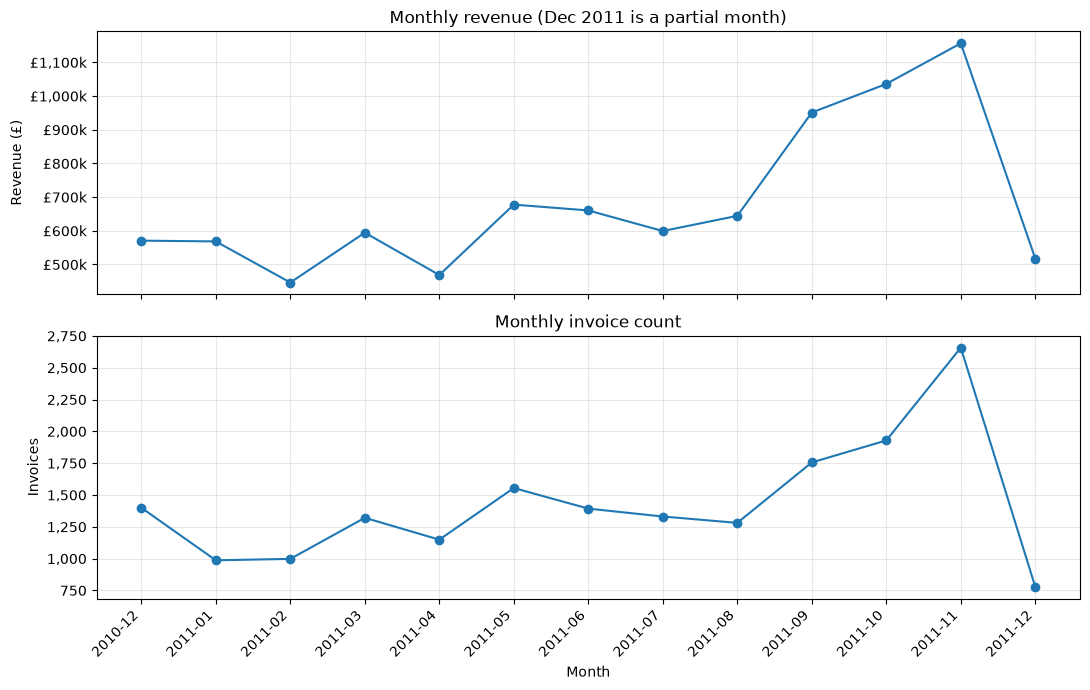

In [50]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})

def format_gbp(axis, scale=1, suffix=""):
    axis.set_major_formatter(FuncFormatter(lambda x, _: f"£{x / scale:,.0f}{suffix}"))

# invoice-level table for AOV and country order value
invoices = (
    df_clean.groupby(["InvoiceNo", "Country", "InvoiceDate"], as_index=False)
    .agg(Revenue=("Revenue", "sum"), Quantity=("Quantity", "sum"), Lines=("StockCode", "count"))
)

# --- sales & revenue trends over time ---
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M").astype(str)
monthly = (
    df_clean.groupby("YearMonth", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Quantity=("Quantity", "sum"),
        Invoices=("InvoiceNo", "nunique"),
        Customers=("CustomerID", "nunique"),
    )
)
monthly["AOV"] = monthly["Revenue"] / monthly["Invoices"]

print("Monthly sales & revenue")
display(monthly)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(monthly["YearMonth"], monthly["Revenue"], marker="o")
axes[0].set_title("Monthly revenue (Dec 2011 is a partial month)")
axes[0].set_ylabel("Revenue (£)")
format_gbp(axes[0].yaxis, scale=1_000, suffix="k")
axes[1].plot(monthly["YearMonth"], monthly["Invoices"], marker="o")
axes[1].set_title("Monthly invoice count")
axes[1].set_ylabel("Invoices")
axes[1].set_xlabel("Month")
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Revenue, sales, and order value by country


,Country,Revenue,Quantity,Invoices,Customers,Lines,AOV,Revenue_pct
0,United Kingdom,"7,285,024.64",4254037,16649,3921,349227,436.86,81.97
1,Netherlands,"285,446.34",200937,95,9,2363,"3,004.70",3.21
2,EIRE,"265,262.46",140383,260,3,7228,"1,016.33",2.98
3,Germany,"228,678.40",119156,457,94,9027,500.39,2.57
4,France,"208,934.31",111429,389,87,8327,535.73,2.35
5,Australia,"138,453.81",84199,57,9,1184,"2,429.01",1.56
6,Spain,"61,558.56",27944,90,30,2480,683.98,0.69
7,Switzerland,"56,443.95",30083,51,21,1842,"1,106.74",0.64
8,Belgium,"41,196.34",23237,98,25,2031,420.37,0.46
9,Sweden,"38,367.83",36078,36,8,450,"1,065.77",0.43


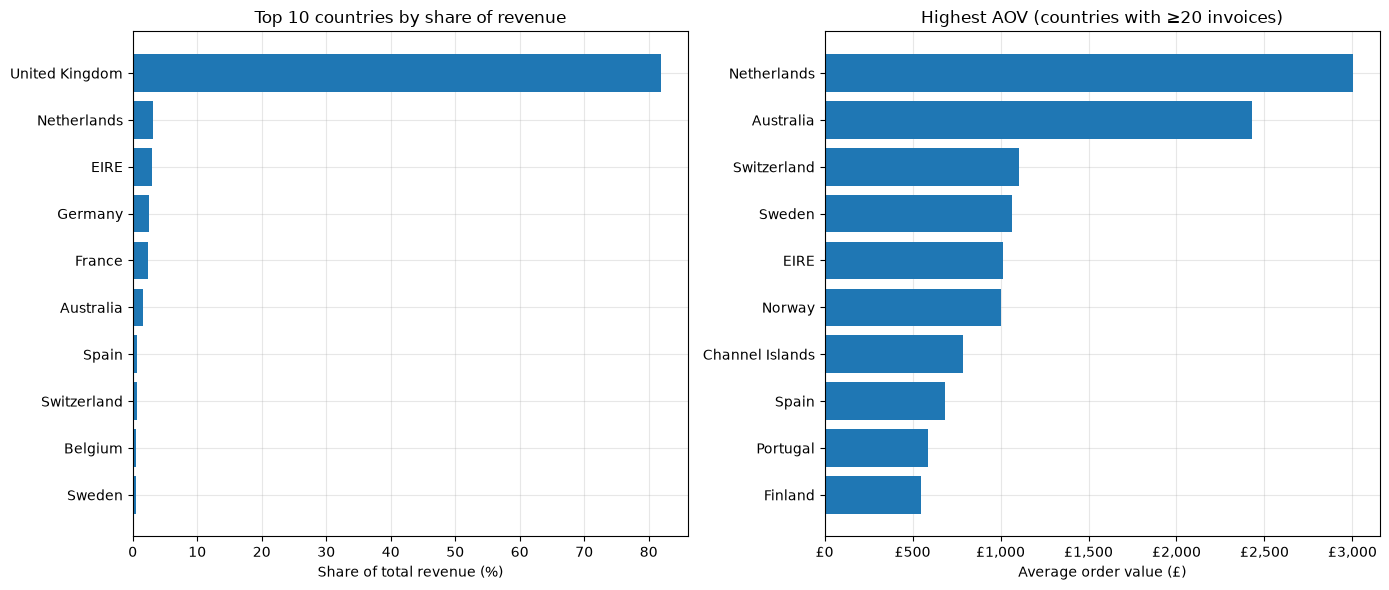

In [51]:
# --- geographic distribution ---
country_stats = (
    df_clean.groupby("Country", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Quantity=("Quantity", "sum"),
        Invoices=("InvoiceNo", "nunique"),
        Customers=("CustomerID", "nunique"),
        Lines=("InvoiceNo", "count"),
    )
)
country_aov = invoices.groupby("Country", as_index=False)["Revenue"].mean().rename(columns={"Revenue": "AOV"})
country_stats = country_stats.merge(country_aov, on="Country")
country_stats["Revenue_pct"] = country_stats["Revenue"] / country_stats["Revenue"].sum() * 100
country_stats = country_stats.sort_values("Revenue", ascending=False).reset_index(drop=True)

print("Revenue, sales, and order value by country")
display(country_stats)

# share (%) keeps the UK visible without a crushed £ scale; AOV is ranked on its own question
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

share = country_stats.head(10).sort_values("Revenue_pct")
axes[0].barh(share["Country"], share["Revenue_pct"])
axes[0].set_title("Top 10 countries by share of revenue")
axes[0].set_xlabel("Share of total revenue (%)")

aov_plot = (
    country_stats.loc[country_stats["Invoices"] >= 20]
    .sort_values("AOV", ascending=True)
    .tail(10)
)
axes[1].barh(aov_plot["Country"], aov_plot["AOV"])
axes[1].set_title("Highest AOV (countries with ≥20 invoices)")
axes[1].set_xlabel("Average order value (£)")
format_gbp(axes[1].xaxis)
plt.tight_layout()
plt.show()

Top 15 products by revenue


,StockCode,Description,Revenue,Quantity,Invoices,Customers,Avg_price
0,23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995,1,1,2.08
1,22423,REGENCY CAKESTAND 3 TIER,"142,264.75",12384,1704,881,11.49
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"100,392.10",36706,1971,856,2.74
3,85099B,JUMBO BAG RED RETROSPOT,"85,040.54",46078,1600,635,1.85
4,23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,416.73",77916,195,138,1.04
5,POST,POSTAGE,"77,803.96",3120,1099,331,24.94
6,47566,PARTY BUNTING,"68,785.23",15283,1380,708,4.50
7,84879,ASSORTED COLOUR BIRD ORNAMENT,"56,413.03",35263,1375,678,1.60
8,M,Manual,"53,419.93",6939,258,201,7.70
9,23084,RABBIT NIGHT LIGHT,"51,251.24",27153,801,450,1.89


Top 15 products by quantity


,StockCode,Description,Revenue,Quantity,Invoices,Customers,Avg_price
0,23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995,1,1,2.08
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,416.73",77916,195,138,1.04
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,"13,558.41",54319,472,307,0.25
3,85099B,JUMBO BAG RED RETROSPOT,"85,040.54",46078,1600,635,1.85
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"100,392.10",36706,1971,856,2.74
5,84879,ASSORTED COLOUR BIRD ORNAMENT,"56,413.03",35263,1375,678,1.60
6,21212,PACK OF 72 RETROSPOT CAKE CASES,"16,381.88",33670,1029,635,0.49
7,22197,POPCORN HOLDER,"23,417.51",30919,632,295,0.76
8,23084,RABBIT NIGHT LIGHT,"51,251.24",27153,801,450,1.89
9,22492,MINI PAINT SET VINTAGE,"16,039.24",26076,325,213,0.62


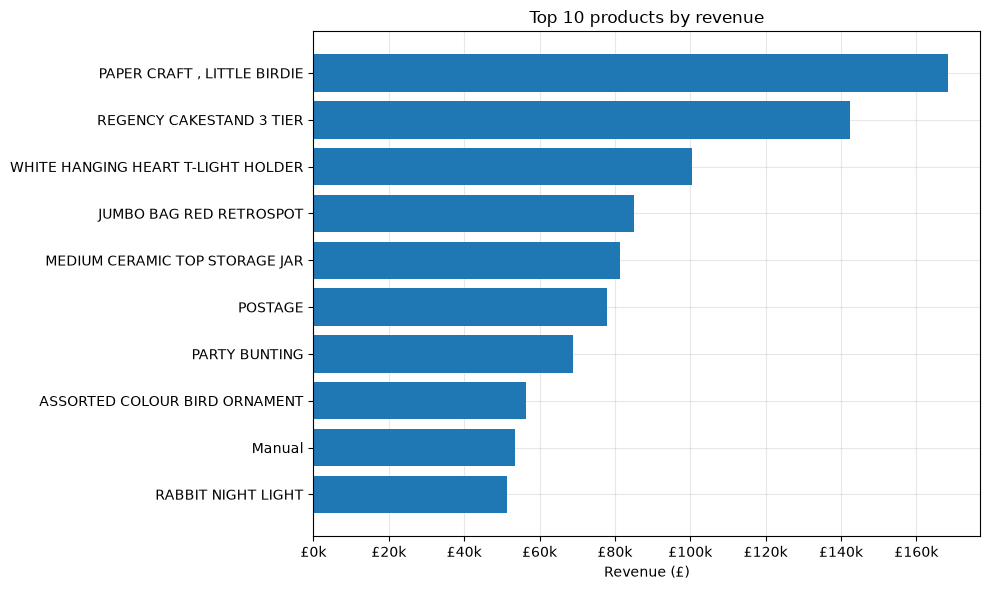

In [52]:
# --- top performing products ---
products = (
    df_clean.groupby(["StockCode", "Description"], as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Quantity=("Quantity", "sum"),
        Invoices=("InvoiceNo", "nunique"),
        Customers=("CustomerID", "nunique"),
    )
)
products["Avg_price"] = products["Revenue"] / products["Quantity"]

print("Top 15 products by revenue")
display(products.sort_values("Revenue", ascending=False).head(15).reset_index(drop=True))

print("Top 15 products by quantity")
display(products.sort_values("Quantity", ascending=False).head(15).reset_index(drop=True))

top_rev = products.sort_values("Revenue", ascending=True).tail(10)
labels = top_rev["Description"].str.slice(0, 42)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(labels, top_rev["Revenue"])
ax.set_title("Top 10 products by revenue")
ax.set_xlabel("Revenue (£)")
format_gbp(ax.xaxis, scale=1_000, suffix="k")
plt.tight_layout()
plt.show()

Invoices: 18,566
AOV (mean): 478.68
AOV (median): 302.40
Mean items per invoice: 278.24
Mean lines per invoice: 21.15

AOV by month


,YearMonth,Revenue,Invoices,AOV
0,2010-12,"570,422.73",1400,407.44
1,2011-01,"568,101.31",987,575.58
2,2011-02,"446,084.92",998,446.98
3,2011-03,"594,081.76",1321,449.72
4,2011-04,"468,374.33",1149,407.64
5,2011-05,"677,355.15",1555,435.60
6,2011-06,"660,046.05",1393,473.83
7,2011-07,"598,962.90",1331,450.01
8,2011-08,"644,051.04",1281,502.77
9,2011-09,"950,690.20",1756,541.40


AOV by country (top 15 by revenue)


,Country,Revenue,Invoices,AOV
0,United Kingdom,"7,285,024.64",16649,436.86
1,Netherlands,"285,446.34",95,"3,004.70"
2,EIRE,"265,262.46",260,"1,016.33"
3,Germany,"228,678.40",457,500.39
4,France,"208,934.31",389,535.73
5,Australia,"138,453.81",57,"2,429.01"
6,Spain,"61,558.56",90,683.98
7,Switzerland,"56,443.95",51,"1,106.74"
8,Belgium,"41,196.34",98,420.37
9,Sweden,"38,367.83",36,"1,065.77"


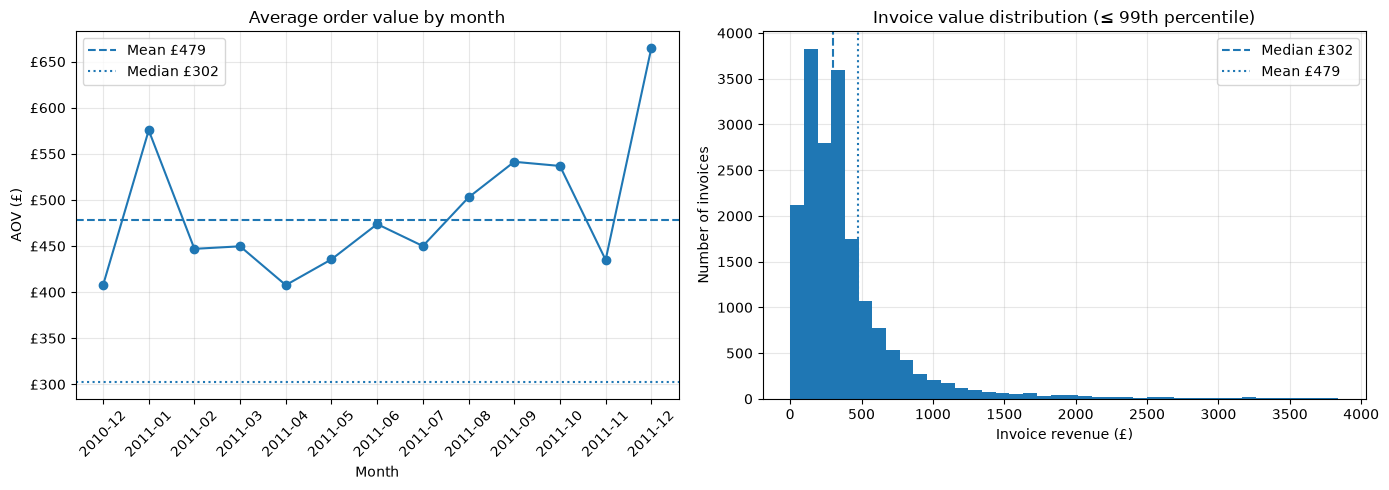

In [53]:
# --- average order value ---
aov_overall = invoices["Revenue"].mean()
aov_median = invoices["Revenue"].median()
print(f"Invoices: {len(invoices):,}")
print(f"AOV (mean): {aov_overall:,.2f}")
print(f"AOV (median): {aov_median:,.2f}")
print(f"Mean items per invoice: {invoices['Quantity'].mean():,.2f}")
print(f"Mean lines per invoice: {invoices['Lines'].mean():,.2f}")

print("\nAOV by month")
display(monthly[["YearMonth", "Revenue", "Invoices", "AOV"]])

print("AOV by country (top 15 by revenue)")
display(country_stats[["Country", "Revenue", "Invoices", "AOV"]].head(15))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(monthly["YearMonth"], monthly["AOV"], marker="o")
axes[0].axhline(aov_overall, linestyle="--", label=f"Mean £{aov_overall:,.0f}")
axes[0].axhline(aov_median, linestyle=":", label=f"Median £{aov_median:,.0f}")
axes[0].set_title("Average order value by month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("AOV (£)")
axes[0].tick_params(axis="x", rotation=45)
format_gbp(axes[0].yaxis)
axes[0].legend()

cap = invoices["Revenue"].quantile(0.99)
clipped = invoices.loc[invoices["Revenue"] <= cap, "Revenue"]
axes[1].hist(clipped, bins=40)
axes[1].axvline(aov_median, linestyle="--", label=f"Median £{aov_median:,.0f}")
axes[1].axvline(aov_overall, linestyle=":", label=f"Mean £{aov_overall:,.0f}")
axes[1].set_title("Invoice value distribution (≤ 99th percentile)")
axes[1].set_xlabel("Invoice revenue (£)")
axes[1].set_ylabel("Number of invoices")
axes[1].legend()
plt.tight_layout()
plt.show()

Revenue by product category


,Category,Revenue,Quantity,Invoices,Products,Lines,Revenue_pct,Revenue_pct_cum
0,Home decor,"2,676,634.76",1381622,15209,982,112893,30.12,30.12
1,Kitchen & tableware,"2,129,642.34",1067364,14333,680,87768,23.96,54.08
2,Other,"1,072,200.38",854433,12745,764,59507,12.06,66.15
3,Bags,"936,789.56",586295,8847,207,41077,10.54,76.69
4,Lighting & candles,"771,770.98",443285,9800,335,28172,8.68,85.37
5,Storage & organisation,"448,198.53",168404,6828,129,15030,5.04,90.41
6,Stationery & paper,"316,492.70",362533,7485,252,24638,3.56,93.97
7,Christmas & seasonal,"288,620.59",230090,4321,137,15757,3.25,97.22
8,Fees / postage,"149,981.25",10225,1519,6,1549,1.69,98.91
9,Toys & games,"73,361.82",49500,2715,46,4687,0.83,99.74


Share of revenue in Other: 12.06%
Top descriptions still in Other


,Description,Revenue
551,POPCORN HOLDER,"23,417.51"
237,FAIRY CAKE FLANNEL ASSORTED COLOUR,"17,291.57"
418,MINI PAINT SET VINTAGE,"16,039.24"
342,HOME BUILDING BLOCK WORD,"15,504.51"
676,SMALL POPCORN HOLDER,"13,789.37"
119,BREAD BIN DINER STYLE IVORY,"13,131.89"
61,ASSORTED COLOUR MINI CASES,"12,107.51"
209,DOUGHNUT LIP GLOSS,"11,615.70"
392,LOVE BUILDING BLOCK WORD,"11,398.71"
719,TRADITIONAL WOODEN SKIPPING ROPE,"9,998.32"


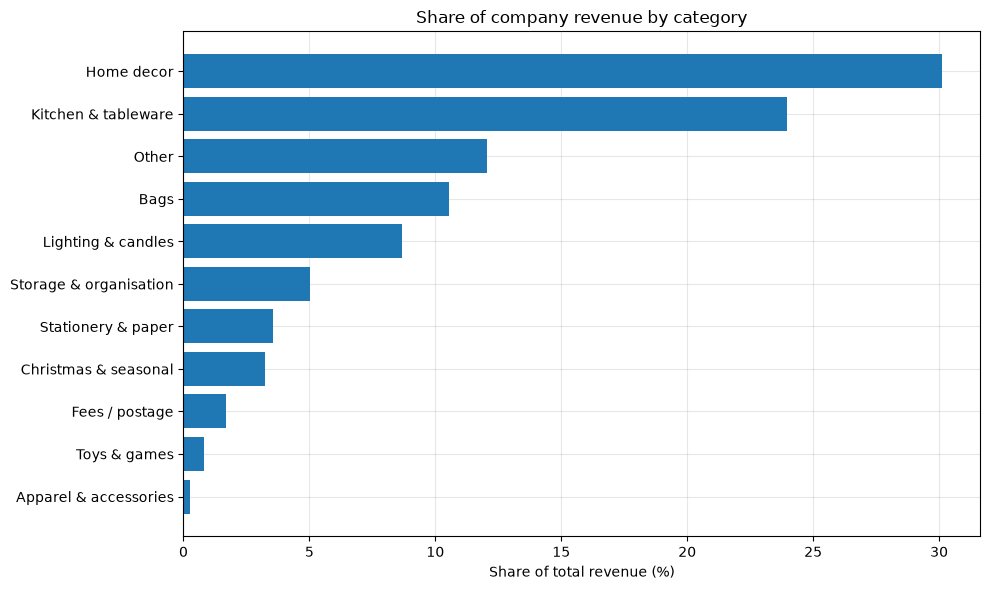

In [54]:
# categories are not in the file — assign from StockCode / Description keywords
def assign_category(stock_code, description):
    code = str(stock_code).strip().upper()
    if code in {
        "POST", "DOT", "M", "D", "S", "AMAZONFEE", "BANK CHARGES", "CRUK", "C2", "PADS", "B"
    }:
        return "Fees / postage"

    text = str(description).upper()

    rules = [
        ("Bags", ["BAG", "PURSE", "SACK", "HANDBAG", "SHOPPER"]),
        ("Lighting & candles", ["T-LIGHT", "TLIGHT", "CANDLE", "LANTERN", "LAMP", "LIGHT"]),
        ("Kitchen & tableware", [
            "CAKESTAND", "CAKE STAND", "MUG", "CUP", "BOWL", "PLATE", "JUG", "JAR",
            "BOTTLE", "CUTLERY", "TEAPOT", "KITCHEN", "TIN", "TRAY", "DISH", "GLASS",
            "NAPKIN", "COASTER", "CHOPPING", "CAKE CASE", "JAM MAKING", "MOULD",
        ]),
        ("Christmas & seasonal", ["CHRISTMAS", "ADVENT", "BAUBLE", "WREATH", "SNOWMAN", "NUTCRACKER"]),
        ("Home decor", [
            "BUNTING", "ORNAMENT", "DECORATION", "DOORMAT", "SIGN", "CLOCK", "MIRROR",
            "FRAME", "CUSHION", "HOOK", "HANGER", "GARDEN", "VASE", "POT", "CERAMIC",
            "HEART", "STAR", "FLOWER", "BIRD", "FOLKART", "BOARD", "PARASOL", "RACK",
            "FAN", "RIBBON",
        ]),
        ("Stationery & paper", ["PAPER", "CARD", "WRAP", "NOTEBOOK", "STICKER", "TAPE", "STAMP", "CRAFT", "LETTER"]),
        ("Storage & organisation", ["BOX", "BASKET", "STORAGE", "DRAWER", "CABINET", "HANGER"]),
        ("Toys & games", ["TOY", "GAME", "DOLL", "GLIDER", "PLAYHOUSE", "JIGSAW"]),
        ("Apparel & accessories", ["T-SHIRT", "SCARF", "HAT", "SOCK", "GLOVE", "JEWELLERY", "NECKLACE", "BRACELET", "EARRING"]),
    ]
    for category, keywords in rules:
        if any(k in text for k in keywords):
            return category
    return "Other"

df_clean["Category"] = [
    assign_category(code, desc)
    for code, desc in zip(df_clean["StockCode"], df_clean["Description"])
]

category_stats = (
    df_clean.groupby("Category", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Quantity=("Quantity", "sum"),
        Invoices=("InvoiceNo", "nunique"),
        Products=("StockCode", "nunique"),
        Lines=("InvoiceNo", "count"),
    )
    .sort_values("Revenue", ascending=False)
    .reset_index(drop=True)
)
category_stats["Revenue_pct"] = category_stats["Revenue"] / category_stats["Revenue"].sum() * 100
category_stats["Revenue_pct_cum"] = category_stats["Revenue_pct"].cumsum()

print("Revenue by product category")
display(category_stats)

print("Share of revenue in Other:", f"{category_stats.loc[category_stats['Category']=='Other', 'Revenue_pct'].sum():.2f}%")

top_in_other = (
    df_clean[df_clean["Category"] == "Other"]
    .groupby("Description", as_index=False)["Revenue"].sum()
    .sort_values("Revenue", ascending=False)
    .head(10)
)
print("Top descriptions still in Other")
display(top_in_other)

plot_df = category_stats.sort_values("Revenue_pct")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_df["Category"], plot_df["Revenue_pct"])
ax.set_title("Share of company revenue by category")
ax.set_xlabel("Share of total revenue (%)")
plt.tight_layout()
plt.show()

Category comparison (revenue, share, customers, invoices)


,Category,Revenue,Revenue_pct,Revenue_pct_cum,Customers,Invoices,Products,Rev_per_invoice,Rev_per_customer
0,Home decor,"2,676,634.76",30.12,30.12,4024,15209,982,175.99,665.17
1,Kitchen & tableware,"2,129,642.34",23.96,54.08,3907,14333,680,148.58,545.08
2,Other,"1,072,200.38",12.06,66.15,3732,12745,764,84.13,287.30
3,Bags,"936,789.56",10.54,76.69,2760,8847,207,105.89,339.42
4,Lighting & candles,"771,770.98",8.68,85.37,3186,9800,335,78.75,242.24
5,Storage & organisation,"448,198.53",5.04,90.41,2541,6828,129,65.64,176.39
6,Stationery & paper,"316,492.70",3.56,93.97,2789,7485,252,42.28,113.48
7,Christmas & seasonal,"288,620.59",3.25,97.22,2224,4321,137,66.79,129.78
8,Fees / postage,"149,981.25",1.69,98.91,548,1519,6,98.74,273.69
9,Toys & games,"73,361.82",0.83,99.74,1351,2715,46,27.02,54.30


Monthly revenue by category


Category,Apparel & accessories,Bags,Christmas & seasonal,Fees / postage,Home decor,Kitchen & tableware,Lighting & candles,Other,Stationery & paper,Storage & organisation,Toys & games
YearMonth,,,,,,,,,,,
2010-12,"3,147.88","33,571.64","19,977.23","5,223.17","175,620.55","144,689.88","67,056.04","60,099.38","17,792.40","39,501.95","3,742.61"
2011-01,"1,290.81","43,596.88",633.97,"5,418.40","142,217.14","217,115.13","49,134.59","60,589.64","17,384.88","27,543.89","3,175.98"
2011-02,"1,175.58","39,769.13",556.52,"3,791.33","149,786.19","120,477.19","33,288.36","51,843.25","18,418.47","23,690.19","3,288.71"
2011-03,"1,358.76","69,969.06",655.45,"10,937.91","170,713.45","150,901.76","37,707.23","84,043.61","27,716.66","33,683.45","6,394.42"
2011-04,"1,267.37","45,438.11",882.27,"13,933.45","141,126.45","112,018.88","36,661.77","68,234.78","23,533.76","20,881.42","4,396.07"
2011-05,"2,517.92","91,440.78","1,732.23","18,112.66","179,322.73","176,371.95","61,562.38","84,587.69","18,946.54","38,405.44","4,354.83"
2011-06,"1,791.35","85,218.84","3,441.95","6,781.13","181,405.90","172,534.53","46,353.11","66,914.98","18,888.63","72,146.62","4,569.01"
2011-07,"2,046.98","77,574.56","10,780.22","7,359.11","177,627.10","165,477.30","43,428.65","71,448.19","17,482.78","22,742.52","2,995.49"
2011-08,"1,427.44","108,254.83","18,511.10","8,536.66","172,802.66","150,930.53","46,371.03","76,941.20","23,522.28","31,048.58","5,704.73"


Category share of each month's revenue (%)


Category,Apparel & accessories,Bags,Christmas & seasonal,Fees / postage,Home decor,Kitchen & tableware,Lighting & candles,Other,Stationery & paper,Storage & organisation,Toys & games
YearMonth,,,,,,,,,,,
2010-12,0.60,5.90,3.50,0.90,30.80,25.40,11.80,10.50,3.10,6.90,0.70
2011-01,0.20,7.70,0.10,1.00,25.00,38.20,8.60,10.70,3.10,4.80,0.60
2011-02,0.30,8.90,0.10,0.80,33.60,27.00,7.50,11.60,4.10,5.30,0.70
2011-03,0.20,11.80,0.10,1.80,28.70,25.40,6.30,14.10,4.70,5.70,1.10
2011-04,0.30,9.70,0.20,3.00,30.10,23.90,7.80,14.60,5.00,4.50,0.90
2011-05,0.40,13.50,0.30,2.70,26.50,26.00,9.10,12.50,2.80,5.70,0.60
2011-06,0.30,12.90,0.50,1.00,27.50,26.10,7.00,10.10,2.90,10.90,0.70
2011-07,0.30,13.00,1.80,1.20,29.70,27.60,7.30,11.90,2.90,3.80,0.50
2011-08,0.20,16.80,2.90,1.30,26.80,23.40,7.20,11.90,3.70,4.80,0.90


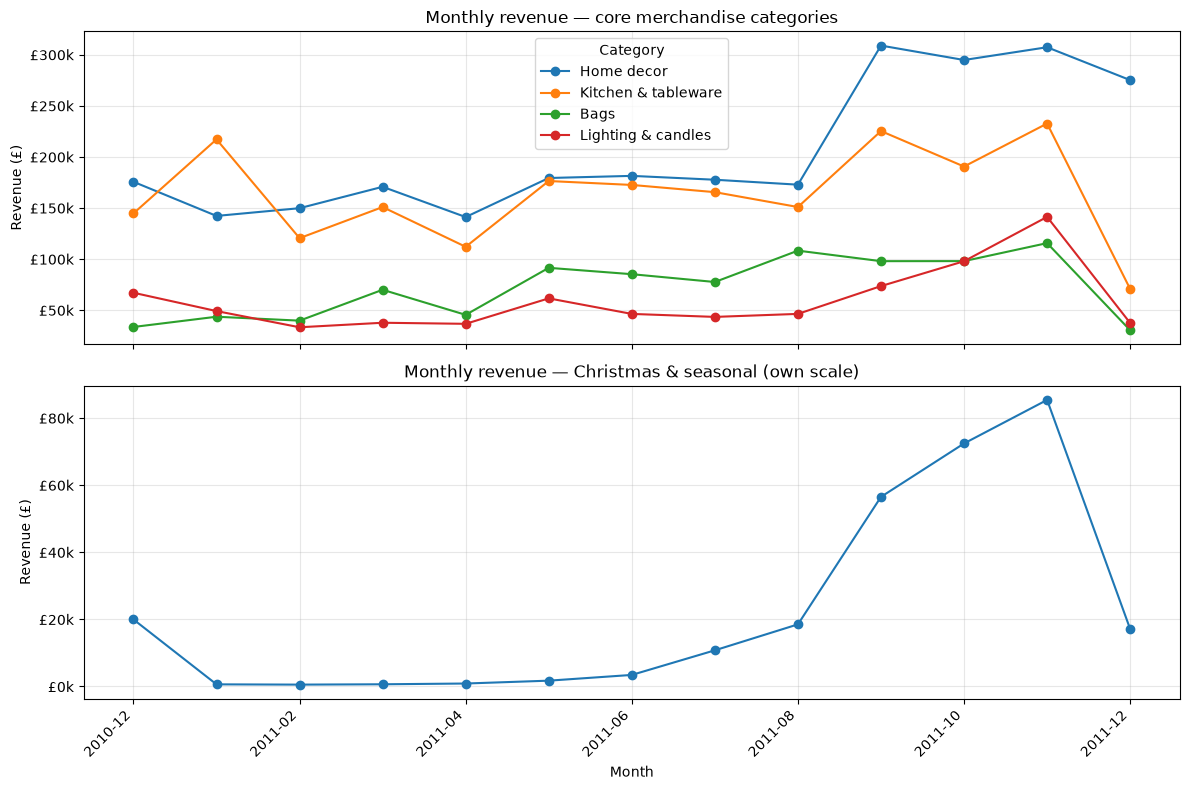

In [55]:
# reuse df_clean["Category"], category_stats, YearMonth
cat_compare = category_stats.merge(
    df_clean.groupby("Category", as_index=False).agg(Customers=("CustomerID", "nunique")),
    on="Category",
)
cat_compare["Rev_per_invoice"] = cat_compare["Revenue"] / cat_compare["Invoices"]
cat_compare["Rev_per_customer"] = cat_compare["Revenue"] / cat_compare["Customers"]
cat_compare = cat_compare[
    ["Category", "Revenue", "Revenue_pct", "Revenue_pct_cum", "Customers", "Invoices", "Products", "Rev_per_invoice", "Rev_per_customer"]
]

print("Category comparison (revenue, share, customers, invoices)")
display(cat_compare)

cat_monthly = (
    df_clean.groupby(["YearMonth", "Category"], as_index=False)["Revenue"].sum()
    .pivot(index="YearMonth", columns="Category", values="Revenue")
    .fillna(0)
)
print("Monthly revenue by category")
display(cat_monthly)

print("Category share of each month's revenue (%)")
display((cat_monthly.div(cat_monthly.sum(axis=1), axis=0) * 100).round(1))

# Christmas is much smaller than decor — overlaying it on one axis hides the seasonal ramp
focus_core = ["Home decor", "Kitchen & tableware", "Bags", "Lighting & candles"]
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
cat_monthly[focus_core].plot(ax=axes[0], marker="o")
axes[0].set_title("Monthly revenue — core merchandise categories")
axes[0].set_ylabel("Revenue (£)")
axes[0].set_xlabel("")
format_gbp(axes[0].yaxis, scale=1_000, suffix="k")
axes[0].legend(title="Category")

axes[1].plot(cat_monthly.index.astype(str), cat_monthly["Christmas & seasonal"], marker="o")
axes[1].set_title("Monthly revenue — Christmas & seasonal (own scale)")
axes[1].set_ylabel("Revenue (£)")
axes[1].set_xlabel("Month")
format_gbp(axes[1].yaxis, scale=1_000, suffix="k")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Category recommendations (from `category_stats` / `df_clean`)

Cleaned sales: **£8,887,209** · **4,339 customers** · **18,536 invoices** · 1 Dec 2010–9 Dec 2011.

| # | Finding | Evidence | Recommendation |
|---|---------|----------|----------------|
| 1 | Decor + kitchen are the company | **54.1%** of revenue (£2.68m + £2.13m). **92.7%** / **90.0%** of customers; **15,209** / **14,333** invoices. Highest revenue per invoice (£176 / £149). | Treat these as core ranging: protect stock of cakestand, t-light/heart decor, bunting, ornaments; put marketing budget here year-round. |
| 2 | Headline categories hide bulk-order risk | Home decor is **30.1%** of sales. *PAPER CRAFT, LITTLE BIRDIE* (£168,470, one customer) is **6.3% of decor** and **1.9% of company**. Kitchen jumps to **£217k in Jan** vs **£120k in Feb** (storage-jar bulk). **82%** of all revenue is UK; decor is **87.7%** UK. | Forecast and reorder on repeat demand, excluding one-off mega invoices. Do not extra-stock from those lines. Run a separate wholesale/key-account view for NL/AU/IE. |
| 3 | Q4 is the seasonal lever | Christmas is only **3.2%** of full-year revenue (£289k) but **80.2%** of that lands **Sep–Dec**. Nov £85.4k vs Feb £0.56k (**~153×**). Lighting Nov £141k is **4.2×** Feb and **12.2%** of November revenue. | Move Christmas + lighting stock in from August. Run a Sep–Nov campaign; attach lighting to decor baskets in peak. Do not judge Christmas on annual share. |
| 4 | Bags and lighting win on breadth, not ticket | Bags **10.5%** revenue, **8,847** invoices, **2,760** customers. Lighting **8.7%**, **9,800** invoices, **3,186** customers. Bags peak Aug–Nov (£108k–£116k). | Use jumbo bags and t-lights as attach items to raise the **median ~£300** order. Keep them in stock through the autumn ramp. |
| 5 | Apparel/toys are not a business; fees are not products | Apparel **0.26%** (£23.5k, 681 customers). Toys **0.83%**. Fees/postage **1.69%**. Other still **12.1%**. Core four (decor, kitchen, bags, lighting) = **73.3%**. | Stop expanding apparel. Report postage off the product P&L. Tighten category tags to shrink Other. |

**Assumptions:** keyword categories on `Description`/`StockCode` (not a merchandising taxonomy); cleaned completed sales only; Dec 2011 is a partial month; no cost/margin, so “high performing” means revenue and customer breadth, not profit. Invoice/customer counts overlap across categories. *LITTLE BIRDIE* sits in Home decor because of “BIRD”.

**Limitations:** ~25% of raw lines had no customer and were dropped; UK dominates, so country mix is weak; outliers inflate category totals; “Other” is residual, not a range.

**Track:** monthly share of decor+kitchen (stay ≥50%); Christmas Sep–Nov revenue vs 2011 (**£214k**); % of category revenue from single-invoice SKUs; bags/lighting invoice count; Other share (down from **12.1%**).